# IMPORTAÇÃO DE BIBLIOTECAS

In [77]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

# IMAGEM E TRATAMENTOS

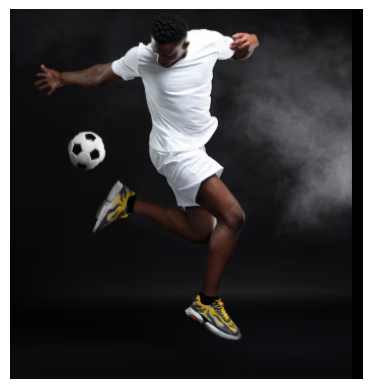

In [78]:
imagem = cv2.imread('/kaggle/input/datasets/josisaias/fotosjogador/Captura de tela 2026-02-17 121049.png') 
imagem = cv2.cvtColor(imagem, cv2.COLOR_BGR2RGB)

plt.imshow(imagem);
plt.axis('off');

# VERIFICANDO FORMATAÇÃO E CORRIGINGO

In [79]:
imagem.shape

(365, 348, 3)

In [80]:
type(imagem)

numpy.ndarray

# NORMALIZAÇÃO 0-1 (BATCH, CANAIS, LARGURA, ALTURA)

In [81]:
#Calculo Mean subtraction
imagem_blob = cv2.dnn.blobFromImage(image = imagem, scalefactor = 1.0/255,
                                   size = (imagem.shape[1], imagem.shape[0]))

imagem_blob.shape

(1, 3, 365, 348)

# REDE NEURAL PRE TREINADA

In [82]:
network = cv2.dnn.readNetFromCaffe('/kaggle/input/datasets/josisaias/frameworkcaffe/pose_deploy_linevec_faster_4_stages.prototxt',
                                  '/kaggle/input/datasets/josisaias/frameworkcaffe/pose_iter_160000.caffemodel')

In [83]:
network.getLayerNames()

('conv1_1',
 'relu1_1',
 'conv1_2',
 'relu1_2',
 'pool1_stage1',
 'conv2_1',
 'relu2_1',
 'conv2_2',
 'relu2_2',
 'pool2_stage1',
 'conv3_1',
 'relu3_1',
 'conv3_2',
 'relu3_2',
 'conv3_3',
 'relu3_3',
 'conv3_4',
 'relu3_4',
 'pool3_stage1',
 'conv4_1',
 'relu4_1',
 'conv4_2',
 'relu4_2',
 'conv4_3_CPM',
 'relu4_3_CPM',
 'conv4_4_CPM',
 'relu4_4_CPM',
 'conv5_1_CPM_L1',
 'relu5_1_CPM_L1',
 'conv5_1_CPM_L2',
 'relu5_1_CPM_L2',
 'conv5_2_CPM_L1',
 'relu5_2_CPM_L1',
 'conv5_2_CPM_L2',
 'relu5_2_CPM_L2',
 'conv5_3_CPM_L1',
 'relu5_3_CPM_L1',
 'conv5_3_CPM_L2',
 'relu5_3_CPM_L2',
 'conv5_4_CPM_L1',
 'relu5_4_CPM_L1',
 'conv5_4_CPM_L2',
 'relu5_4_CPM_L2',
 'conv5_5_CPM_L1',
 'conv5_5_CPM_L2',
 'concat_stage2',
 'Mconv1_stage2_L1',
 'Mrelu1_stage2_L1',
 'Mconv1_stage2_L2',
 'Mrelu1_stage2_L2',
 'Mconv2_stage2_L1',
 'Mrelu2_stage2_L1',
 'Mconv2_stage2_L2',
 'Mrelu2_stage2_L2',
 'Mconv3_stage2_L1',
 'Mrelu3_stage2_L1',
 'Mconv3_stage2_L2',
 'Mrelu3_stage2_L2',
 'Mconv4_stage2_L1',
 'Mrelu4_sta

In [84]:
len(network.getLayerNames())

127

# Previsão dos pontos corporais

In [85]:
network.setInput(imagem_blob)
output = network.forward()

# bacth, pontos detectados, localização dos pontos x, y

In [86]:
output.shape

(1, 44, 46, 44)

In [87]:
posicao_largura = output.shape[3] 
posicao_altura = output.shape[2]

posicao_largura, posicao_altura

(44, 46)

In [88]:
numero_pontos = 15
pontos = [] #criando lista vazia para armazenar as cordenadas x e y 
threshold = 0.1

for i in range(numero_pontos):
    #print(i)
    mapa_confianca = output[0, i, :, :] #pega uma unica imagem busca os 15 pontos no for e o :, : representam largura e altura
    #print(mapa_confianca) #mostra o resultado em forma de matriz numpy
    print(len(mapa_confianca)) #quantos pontos para representar cada area do corpo 44


46
46
46
46
46
46
46
46
46
46
46
46
46
46
46


In [89]:
#minMaxLoc funcao do cv2 que busca o minimo e o maximo valor dando a sua posição que vamos traçar na imagem como pontos corporais

In [90]:
for i in range(numero_pontos): #criando um loop para cada 15 pontos
    mapa_confianca = output[0, i, :, :] #gerando uma matriz de confianca 44 resultados para cada ponto corporal
    _, confianca, _, ponto = cv2.minMaxLoc(mapa_confianca) #pegando os valores maximos e atribuindo a variavel confiança e pontos
    print(confianca)
    print(ponto)
    x = int((imagem.shape[1] * ponto[0]) / posicao_largura) #pegando as cordenadas do mapa pequeno e multiplicando pelo da imagem dps / pelo redimensionamento anterior
    y = int((imagem.shape[0] * ponto[1]) / posicao_altura)
    print(x, y)
    if confianca > threshold:
        cv2.circle(imagem, (x,y), 5, (0,255,0), thickness = -1)
        cv2.putText(imagem, '{}'.format(i), (x,y), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (255,0,0))
        pontos.append((x,y))
    else:
        pontos.append(None)

0.6731043457984924
(18, 0)
142 0
0.6476541757583618
(20, 6)
158 47
0.6606070399284363
(16, 5)
126 39
0.6633597016334534
(11, 7)
87 55
0.757085382938385
(6, 8)
47 63
0.48196080327033997
(24, 4)
189 31
0.286922425031662
(29, 4)
229 31
0.356962651014328
(28, 4)
221 31
0.5168798565864563
(21, 18)
166 142
0.781485378742218
(27, 25)
213 198
0.757275402545929
(24, 35)
189 277
0.3256155550479889
(20, 18)
158 142
0.6075431704521179
(23, 26)
181 206
0.47421127557754517
(15, 24)
118 190
0.7562510371208191
(20, 11)
158 87


In [91]:
pontos

[(142, 0),
 (158, 47),
 (126, 39),
 (87, 55),
 (47, 63),
 (189, 31),
 (229, 31),
 (221, 31),
 (166, 142),
 (213, 198),
 (189, 277),
 (158, 142),
 (181, 206),
 (118, 190),
 (158, 87)]

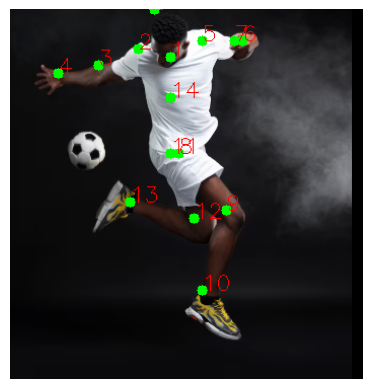

In [92]:
plt.imshow(imagem);
plt.axis('off');

In [93]:
ponto_conexoes = [[0,1], [1,2], [2,3], [3,4], [1,5], [5,6], [6,7], [1,14], [14, 8], [8,9], [9, 10], [14, 11], [11, 12], [12, 13]] 

ponto_conexoes

[[0, 1],
 [1, 2],
 [2, 3],
 [3, 4],
 [1, 5],
 [5, 6],
 [6, 7],
 [1, 14],
 [14, 8],
 [8, 9],
 [9, 10],
 [14, 11],
 [11, 12],
 [12, 13]]

In [94]:
for conexao in ponto_conexoes: #LOOP PARA LER CADA VALOR
    #print(conexao)
    parteA = conexao[0]
    parteB= conexao[1]
    #print(parteA, parteB)
    if pontos[parteA] and pontos[parteB]:
        cv2.line(imagem, pontos[parteA], pontos[parteB], (0,0,255), 2) #REALIZANDO A CONEXAO DOS PONTOS

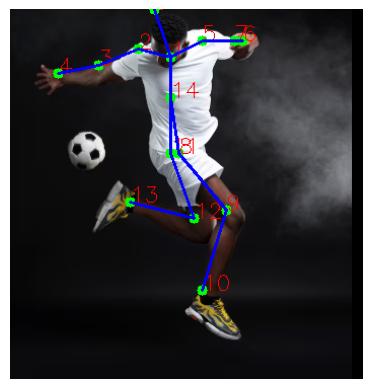

In [95]:
plt.imshow(imagem);
plt.axis('off');